# Генерация подписей к изображениям с помощью RNN
В этом упражнении вы реализуете простые (vanilla) рекуррентные нейронные сети (RNN) и с их помощью обучите модель, которая умеет генерировать новые подписи к изображениям.

In [1]:
# @title Настройка окружения (запустите эту ячейку первой)
# В Google Colab ячейка подключит ваш Google Диск и перейдёт в папку с лабораторной.
# При локальном запуске (Jupyter) ничего подключать не нужно: достаточно открыть
# ноутбук из папки лабораторной.

# Путь к папке лабораторной внутри «Моего диска», например 'DL/assignment2'.
# Если оставить пустым, папка будет найдена автоматически.
FOLDERNAME = ''  # @param {type:"string"}

import glob
import os
import sys

NOTEBOOK = 'RNN_Captioning_pytorch.ipynb'

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive'
    lab_dir = None
    if FOLDERNAME:
        lab_dir = os.path.join(DRIVE_ROOT, FOLDERNAME.strip('/'))
    else:
        # Ищем на Диске папку, в которой лежат этот ноутбук и пакет dlcv.
        for depth in range(5):
            pattern = os.path.join(DRIVE_ROOT, *['*'] * depth, 'dlcv', '__init__.py')
            found = [os.path.dirname(os.path.dirname(p)) for p in sorted(glob.glob(pattern))]
            found = [d for d in found if os.path.isfile(os.path.join(d, NOTEBOOK))]
            if found:
                # Если копий несколько, берём ту, где ноутбук менялся последним.
                found.sort(key=lambda d: os.path.getmtime(os.path.join(d, NOTEBOOK)),
                           reverse=True)
                lab_dir = found[0]
                if len(found) > 1:
                    print('Найдено несколько папок с лабораторной:', *found, sep='\n  ')
                    print('Используется', lab_dir, '(другую папку можно указать в FOLDERNAME)')
                break
    if lab_dir is None or not os.path.isdir(os.path.join(lab_dir, 'dlcv')):
        raise FileNotFoundError(
            'Не удалось найти папку с лабораторной на Google Диске. Укажите путь '
            'к ней в FOLDERNAME, например: FOLDERNAME = \'DL/assignment2\'')
    os.chdir(lab_dir)

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки лабораторной.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# В Colab используется IPython 7.x, и на Python 3.12+ его расширение autoreload
# не загружается: ему нужен удалённый из Python модуль imp. Подставляем
# совместимую замену (расширению нужна только функция reload).
import IPython
if (sys.version_info >= (3, 12) and IPython.version_info[0] < 8
        and 'imp' not in sys.modules):
    import importlib
    import types
    sys.modules['imp'] = types.ModuleType('imp')
    sys.modules['imp'].reload = importlib.reload

from dlcv.coco_utils import ensure_coco_captioning
ensure_coco_captioning()
print('Рабочая папка:', os.getcwd())

Рабочая папка: assignment2 (локальный путь скрыт)


> **Как редактировать файлы в Colab.** Часть кода нужно дописывать не в ноутбуках, а в файлах пакета `dlcv/` (например, `dlcv/layers.py`). Откройте панель «Файлы» (значок папки слева), найдите папку лабораторной в `drive/MyDrive/…` и дважды щёлкните по нужному файлу — он откроется в редакторе справа. Сохраните изменения (Ctrl+S). Благодаря `%autoreload` ноутбук подхватит новую версию кода без перезапуска среды выполнения.

In [2]:

# Подготовительная ячейка.
import time, os, json
import numpy as np
import torch
import matplotlib.pyplot as plt

from dlcv.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from dlcv.rnn_layers_pytorch import *
from dlcv.captioning_solver_pytorch import CaptioningSolverPytorch
from dlcv.classifiers.rnn_pytorch import CaptioningRNN
from dlcv.coco_utils import load_coco_data, sample_coco_minibatch, decode_captions
from dlcv.image_utils import image_from_url

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # Размер графиков по умолчанию.
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """ Возвращает относительную ошибку. """
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

# Набор данных COCO
В этом упражнении используется выпуск 2014 года набора данных [COCO](https://cocodataset.org/) — стандартного полигона для экспериментов с генерацией подписей к изображениям. Каждое изображение в нём сопровождается несколькими (обычно пятью) подписями, которые написали исполнители на платформе Amazon Mechanical Turk.

В лабораторную работу входит не весь набор (в нём более 80 000 обучающих и 40 000 валидационных изображений), а его подмножество: 20 000 обучающих и 10 000 валидационных изображений, примерно по 5 подписей к каждому. Все файлы с данными лежат в папке `dlcv/datasets/coco_captioning`.

**Признаки изображений.** Данные уже предобработаны: признаки (features) изображений извлечены за вас. Для каждого изображения взят выход слоя fc7 сети VGG-16, предварительно обученной на ImageNet, — вектор из 4096 чисел. Чтобы сократить время обработки и объём памяти, размерность признаков снижена с 4096 до 512 методом главных компонент (PCA). В лабораторную работу входят только эти сжатые признаки (512 чисел на изображение) — файлы `train2014_vgg16_fc7_pca.h5` и `val2014_vgg16_fc7_pca.h5`. Исходные 4096-мерные признаки в неё не включены.

**Изображения.** Сами изображения в лабораторную работу тоже не входят. Все они взяты с сайта Flickr, а их адреса (URL) для обучающей и валидационной выборок хранятся в файлах `train2014_urls.txt` и `val2014_urls.txt`. Для визуализации изображения скачиваются по этим адресам «на лету». Некоторые ссылки могут уже не работать.

**Подписи.** Работать непосредственно со строками неэффективно, поэтому мы будем использовать закодированные подписи (они хранятся в файле `coco2014_captions.h5`). Каждому слову присвоен целочисленный идентификатор (ID), так что подпись можно представить последовательностью целых чисел. Соответствие между идентификаторами и словами хранится в файле `coco2014_vocab.json`; чтобы преобразовать массивы NumPy с идентификаторами обратно в строки, используйте функцию `decode_captions` из файла `dlcv/coco_utils.py`.

**Специальные токены.** В словарь добавлено несколько специальных токенов, и всё, что связано с их обработкой, уже реализовано за вас. В начало каждой подписи добавлен специальный токен `<START>`, а в конец — токен `<END>`. Редкие слова заменены специальным токеном `<UNK>` (от англ. unknown — «неизвестное»). Кроме того, поскольку модель обучается на мини-батчах, в которых подписи имеют разную длину, короткие подписи дополнены после токена `<END>` специальными токенами `<NULL>`; для токенов `<NULL>` потери и градиент не вычисляются.

Все данные COCO (подписи, признаки, URL-адреса и словарь) загружаются функцией `load_coco_data` из файла `dlcv/coco_utils.py`. Запустите следующую ячейку, чтобы загрузить их:

In [3]:
# Загружаем данные COCO с диска в словарь (dict).
# Во всей лабораторной работе используются признаки пониженной размерности
# (после PCA). Исходные 4096-мерные признаки в комплект лабораторной не входят,
# поэтому флаг pca_features ниже менять не нужно: с pca_features=False
# загрузка завершится ошибкой.
data = load_coco_data(pca_features=True)

# Выводим все ключи словаря data, а также тип и форму (или длину) значений.
for k, v in data.items():
    if type(v) == np.ndarray:
        print(k, type(v), v.shape, v.dtype)
    else:
        print(k, type(v), len(v))

train_captions <class 'numpy.ndarray'> (96721, 17) int32
train_image_idxs <class 'numpy.ndarray'> (96721,) int32
val_captions <class 'numpy.ndarray'> (48410, 17) int32
val_image_idxs <class 'numpy.ndarray'> (48410,) int32
train_features <class 'numpy.ndarray'> (20000, 512) float32
val_features <class 'numpy.ndarray'> (10000, 512) float32
idx_to_word <class 'list'> 1004
word_to_idx <class 'dict'> 1004
train_urls <class 'numpy.ndarray'> (20000,) <U63
val_urls <class 'numpy.ndarray'> (10000,) <U63


## Посмотрим на данные
Прежде чем работать с набором данных, всегда полезно посмотреть на примеры из него.

Функция `sample_coco_minibatch` из файла `dlcv/coco_utils.py` выбирает случайные мини-батчи из структуры данных, которую возвращает `load_coco_data`. Запустите следующую ячейку: она выберет небольшой мини-батч из обучающей выборки и покажет изображения вместе с подписями. Запустите её несколько раз и посмотрите на результаты — так вы лучше почувствуете, как устроен набор данных.

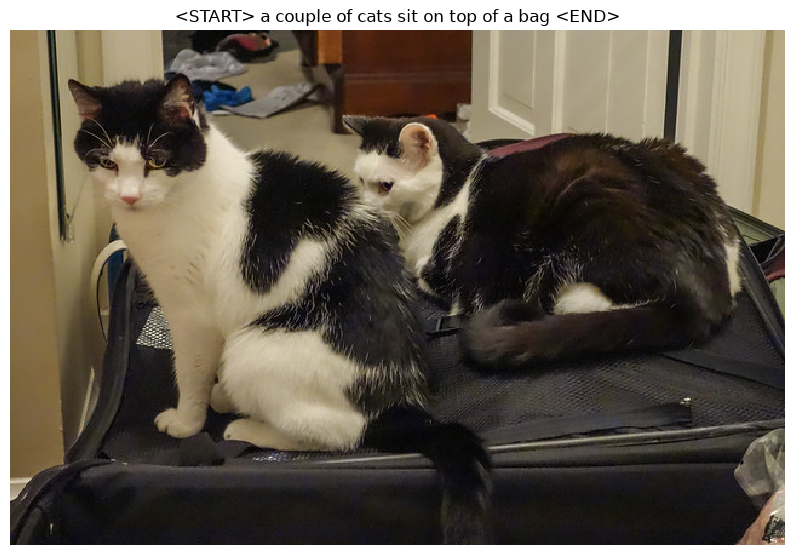

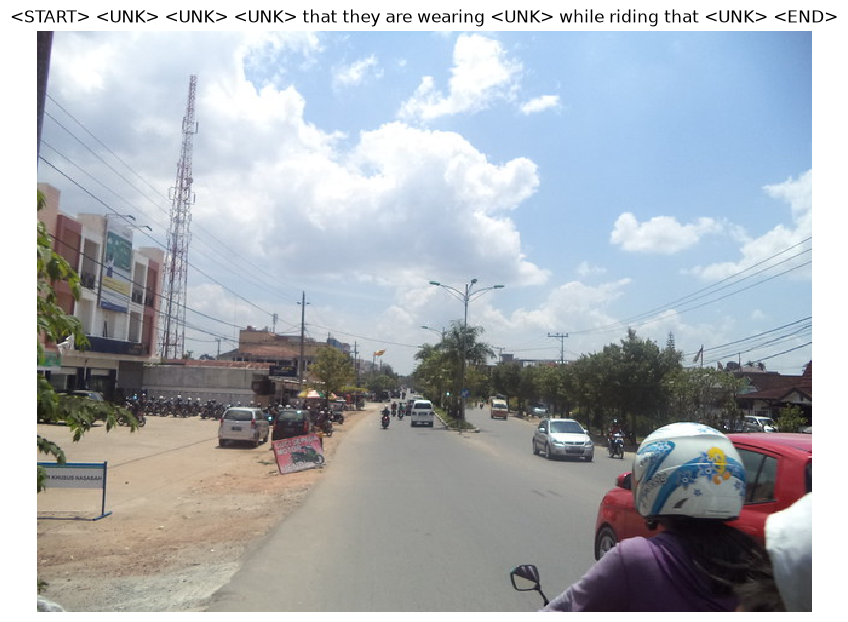

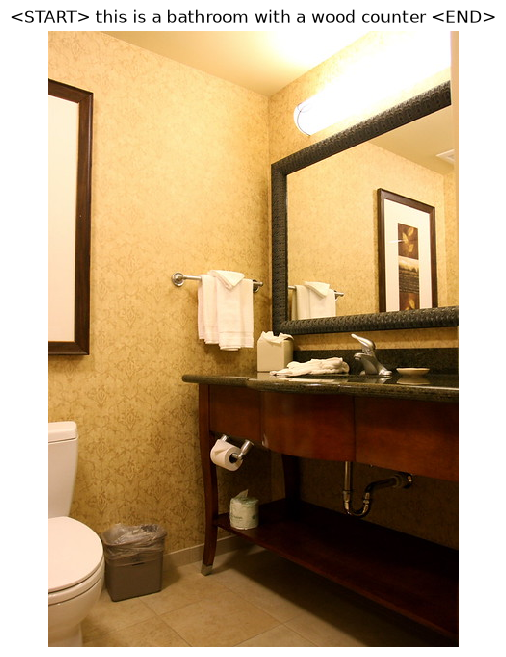

In [4]:
# Выбираем мини-батч и показываем изображения с подписями.
# Если появилось сообщение об ошибке, значит, этого URL больше не существует —
# не волнуйтесь! Выбирать новые примеры можно сколько угодно раз.
batch_size = 3

captions, features, urls = sample_coco_minibatch(data, batch_size=batch_size)
for i, (caption, url) in enumerate(zip(captions, urls)):
    img = image_from_url(url)
    # Пропускаем недоступные URL.
    if img is None: continue
    plt.imshow(img)
    plt.axis('off')
    caption_str = decode_captions(caption, data['idx_to_word'])
    plt.title(caption_str)
    plt.show()

# Рекуррентная нейронная сеть
Как обсуждалось на лекции, для генерации подписей к изображениям мы будем использовать языковые модели на основе рекуррентных нейронных сетей (RNN). Файл `dlcv/rnn_layers_pytorch.py` содержит реализации различных типов слоёв, нужных для рекуррентных нейронных сетей, а в файле `dlcv/classifiers/rnn_pytorch.py` из этих слоёв собирается модель генерации подписей к изображениям.

Сначала реализуем различные типы слоёв RNN в файле `dlcv/rnn_layers_pytorch.py`.

_Необязательное дополнительное чтение для более глубокого понимания RNN — глава о рекуррентных сетях из книги «Deep Learning»: https://www.deeplearningbook.org/contents/rnn.html#pf7_

# Простая RNN: прямой проход для одного шага по времени
Откройте файл `dlcv/rnn_layers_pytorch.py`. В нём реализуются прямые проходы для различных типов слоёв, которые часто используются в рекуррентных нейронных сетях. Обратите внимание: поскольку мы используем PyTorch, обратный проход выполнит за нас механизм автоматического дифференцирования PyTorch (autograd).

Сначала реализуйте функцию `rnn_step_forward` — прямой проход простой (vanilla) рекуррентной нейронной сети для одного шага по времени. Затем запустите следующую ячейку, чтобы проверить свою реализацию. Ошибка должна быть порядка e-8 или меньше.

In [5]:
N, D, H = 3, 10, 4

x = torch.from_numpy(np.linspace(-0.4, 0.7, num=N*D).reshape(N, D))
prev_h = torch.from_numpy(np.linspace(-0.2, 0.5, num=N*H).reshape(N, H))
Wx = torch.from_numpy(np.linspace(-0.1, 0.9, num=D*H).reshape(D, H))
Wh = torch.from_numpy(np.linspace(-0.3, 0.7, num=H*H).reshape(H, H))
b = torch.from_numpy(np.linspace(-0.2, 0.4, num=H))

next_h = rnn_step_forward(x, prev_h, Wx, Wh, b).numpy()
expected_next_h = np.asarray([
  [-0.58172089, -0.50182032, -0.41232771, -0.31410098],
  [ 0.66854692,  0.79562378,  0.87755553,  0.92795967],
  [ 0.97934501,  0.99144213,  0.99646691,  0.99854353]])

print('ошибка next_h: ', rel_error(expected_next_h, next_h))

ошибка next_h:  6.292421426471037e-09


# Простая RNN: обратный проход для одного шага по времени
Поскольку функция `rnn_step_forward` реализована на PyTorch, реализовывать `rnn_step_backward` НЕ нужно. Обратный проход, который вычисляет autograd PyTorch, можно проверить с помощью численной проверки градиента.

Впрочем, если хочется приключений, можете попробовать реализовать `rnn_step_backward` самостоятельно. В этой лабораторной работе это не требуется.

In [6]:
from dlcv.rnn_layers_pytorch import rnn_step_forward

# Создаём тестовые входные данные
np.random.seed(231)
N, D, H = 4, 5, 6
x = torch.from_numpy(np.random.randn(N, D))
h = torch.from_numpy(np.random.randn(N, H))
Wx = torch.from_numpy(np.random.randn(D, H))
Wh = torch.from_numpy(np.random.randn(H, H))
b = torch.from_numpy(np.random.randn(H))

# Включаем отслеживание градиентов и выполняем прямой проход RNN
for tensor in [x, h, Wx, Wh, b]:
  tensor.requires_grad_()
next_h = rnn_step_forward(x, h, Wx, Wh, b)

# Имитируем случайный градиент, пришедший сверху (upstream), и выполняем
# обратный проход с помощью autograd PyTorch.
dnext_h = torch.from_numpy(np.random.randn(*next_h.shape))
next_h.backward(dnext_h)

# Собираем градиенты в отдельные массивы numpy
dx = x.grad.detach().numpy()
dh = h.grad.detach().numpy()
dWx = Wx.grad.detach().numpy()
dWh = Wh.grad.detach().numpy()
db = b.grad.detach().numpy()
dnext_h = dnext_h.detach().numpy()

# Тестовые входные данные тоже преобразуем в массивы numpy
x =  x.detach().numpy()
h =  h.detach().numpy()
Wx = Wx.detach().numpy()
Wh = Wh.detach().numpy()
b =  b.detach().numpy()

# Оборачиваем прямой проход, чтобы он принимал и возвращал массивы numpy.
# С помощью `torch.no_grad()` явно отключаем отслеживание градиентов.
def rnn_step_forward_numpy(x, h, Wx, Wh, b):
  with torch.no_grad():
    return rnn_step_forward(
        torch.from_numpy(x),
        torch.from_numpy(h),
        torch.from_numpy(Wx),
        torch.from_numpy(Wh),
        torch.from_numpy(b),
    ).numpy()

# Вычисляем численные градиенты и сравниваем.
fx = lambda x: rnn_step_forward_numpy(x, h, Wx, Wh, b)
fh = lambda h: rnn_step_forward_numpy(x, h, Wx, Wh, b)
fWx = lambda Wx: rnn_step_forward_numpy(x, h, Wx, Wh, b)
fWh = lambda Wh: rnn_step_forward_numpy(x, h, Wx, Wh, b)
fb = lambda b: rnn_step_forward_numpy(x, h, Wx, Wh, b)

dx_num = eval_numerical_gradient_array(fx, x, dnext_h)
dh_num = eval_numerical_gradient_array(fh, h, dnext_h)
dWx_num = eval_numerical_gradient_array(fWx, Wx, dnext_h)
dWh_num = eval_numerical_gradient_array(fWh, Wh, dnext_h)
db_num = eval_numerical_gradient_array(fb, b, dnext_h)

# Ошибки должны быть порядка 1e-9 или меньше
print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dh: ', rel_error(dh_num, dh))
print('ошибка dWx: ', rel_error(dWx_num, dWx))
print('ошибка dWh: ', rel_error(dWh_num, dWh))
print('ошибка db: ', rel_error(db_num, db))

ошибка dx:  2.319932372313319e-10
ошибка dh:  2.682833932515051e-10
ошибка dWx:  8.820244454238703e-10
ошибка dWh:  4.703287554560559e-10
ошибка db:  1.5956895526227225e-11


# Простая RNN: прямой проход
Теперь, когда прямой проход простой RNN для одного шага по времени готов, используйте его, чтобы реализовать RNN, которая обрабатывает целую последовательность данных.

В файле `dlcv/rnn_layers_pytorch.py` реализуйте функцию `rnn_forward`. Для этого используйте функцию `rnn_step_forward`, которую вы написали выше. Затем запустите следующую ячейку, чтобы проверить свою реализацию. Ошибка должна быть порядка `e-7` или меньше.

In [7]:
from dlcv.rnn_layers_pytorch import rnn_forward

N, T, D, H = 2, 3, 4, 5

x = torch.from_numpy(np.linspace(-0.1, 0.3, num=N*T*D).reshape(N, T, D))
h0 = torch.from_numpy(np.linspace(-0.3, 0.1, num=N*H).reshape(N, H))
Wx = torch.from_numpy(np.linspace(-0.2, 0.4, num=D*H).reshape(D, H))
Wh = torch.from_numpy(np.linspace(-0.4, 0.1, num=H*H).reshape(H, H))
b = torch.from_numpy(np.linspace(-0.7, 0.1, num=H))

h = rnn_forward(x, h0, Wx, Wh, b).numpy()
expected_h = np.asarray([
  [
    [-0.42070749, -0.27279261, -0.11074945,  0.05740409,  0.22236251],
    [-0.39525808, -0.22554661, -0.0409454,   0.14649412,  0.32397316],
    [-0.42305111, -0.24223728, -0.04287027,  0.15997045,  0.35014525],
  ],
  [
    [-0.55857474, -0.39065825, -0.19198182,  0.02378408,  0.23735671],
    [-0.27150199, -0.07088804,  0.13562939,  0.33099728,  0.50158768],
    [-0.51014825, -0.30524429, -0.06755202,  0.17806392,  0.40333043]]])
print('ошибка h: ', rel_error(expected_h, h))

ошибка h:  7.728466151011529e-08


# Простая RNN: обратный проход
Как и раньше, обратный проход, который вычисляет autograd PyTorch, можно проверить с помощью численной проверки градиента. При желании можете также попробовать реализовать `rnn_backward` самостоятельно, но в этой лабораторной работе это не требуется.

In [8]:
from dlcv.rnn_layers_pytorch import rnn_forward

# Создаём тестовые входные данные
np.random.seed(231)
N, D, T, H = 2, 3, 10, 5
x = torch.from_numpy(np.random.randn(N, T, D))
h0 = torch.from_numpy(np.random.randn(N, H))
Wx = torch.from_numpy(np.random.randn(D, H))
Wh = torch.from_numpy(np.random.randn(H, H))
b = torch.from_numpy(np.random.randn(H))

# Включаем отслеживание градиентов и выполняем прямой проход
for tensor in [x, h0, Wx, Wh, b]:
  tensor.requires_grad_()
h = rnn_forward(x, h0, Wx, Wh, b)

# Имитируем случайный градиент, пришедший сверху (upstream), и выполняем
# обратный проход с помощью autograd PyTorch.
dh = torch.from_numpy(np.random.randn(*h.shape))
h.backward(dh)

# Собираем градиенты в отдельные массивы numpy
dx = x.grad.detach().numpy()
dh0 = h0.grad.detach().numpy()
dWx = Wx.grad.detach().numpy()
dWh = Wh.grad.detach().numpy()
db = b.grad.detach().numpy()
dh = dh.detach().numpy()

# Тестовые входные данные тоже преобразуем в массивы numpy
x =  x.detach().numpy()
h0 =  h0.detach().numpy()
Wx = Wx.detach().numpy()
Wh = Wh.detach().numpy()
b =  b.detach().numpy()

# Оборачиваем прямой проход, чтобы он принимал и возвращал массивы numpy.
# С помощью `torch.no_grad()` явно отключаем отслеживание градиентов.
def rnn_forward_numpy(x, h0, Wx, Wh, b):
  with torch.no_grad():
    return rnn_forward(
        torch.from_numpy(x),
        torch.from_numpy(h0),
        torch.from_numpy(Wx),
        torch.from_numpy(Wh),
        torch.from_numpy(b),
    ).numpy()


fx = lambda x: rnn_forward_numpy(x, h0, Wx, Wh, b)
fh0 = lambda h0: rnn_forward_numpy(x, h0, Wx, Wh, b)
fWx = lambda Wx: rnn_forward_numpy(x, h0, Wx, Wh, b)
fWh = lambda Wh: rnn_forward_numpy(x, h0, Wx, Wh, b)
fb = lambda b: rnn_forward_numpy(x, h0, Wx, Wh, b)

dx_num = eval_numerical_gradient_array(fx, x, dh)
dh0_num = eval_numerical_gradient_array(fh0, h0, dh)
dWx_num = eval_numerical_gradient_array(fWx, Wx, dh)
dWh_num = eval_numerical_gradient_array(fWh, Wh, dh)
db_num = eval_numerical_gradient_array(fb, b, dh)

# Ошибки должны быть порядка 1e-6 или меньше
print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dh0: ', rel_error(dh0_num, dh0))
print('ошибка dWx: ', rel_error(dWx_num, dWx))
print('ошибка dWh: ', rel_error(dWh_num, dWh))
print('ошибка db: ', rel_error(db_num, db))

ошибка dx:  1.5402322184213243e-09
ошибка dh0:  3.38326056377258e-09
ошибка dWx:  7.238347597134815e-09
ошибка dWh:  1.3157179304570955e-07
ошибка db:  1.5384079038256828e-10


# Векторное представление слов: прямой проход
В системах глубокого обучения слова обычно представляют векторами — это называется векторным представлением слов (word embedding). Каждому слову словаря сопоставляется вектор, и эти векторы обучаются вместе с остальной системой.

В файле `dlcv/rnn_layers_pytorch.py` реализуйте функцию `word_embedding_forward`, которая преобразует слова (представленные целыми числами) в векторы. Запустите следующую ячейку, чтобы проверить свою реализацию. Ошибка должна быть порядка `e-8` или меньше.

In [9]:
N, T, V, D = 2, 4, 5, 3

x = torch.from_numpy(np.asarray([[0, 3, 1, 2], [2, 1, 0, 3]]))
W = torch.from_numpy(np.linspace(0, 1, num=V*D).reshape(V, D))

out = word_embedding_forward(x, W).numpy()
expected_out = np.asarray([
 [[ 0.,          0.07142857,  0.14285714],
  [ 0.64285714,  0.71428571,  0.78571429],
  [ 0.21428571,  0.28571429,  0.35714286],
  [ 0.42857143,  0.5,         0.57142857]],
 [[ 0.42857143,  0.5,         0.57142857],
  [ 0.21428571,  0.28571429,  0.35714286],
  [ 0.,          0.07142857,  0.14285714],
  [ 0.64285714,  0.71428571,  0.78571429]]])

print('ошибка out: ', rel_error(expected_out, out))

ошибка out:  1.0000000094736443e-08


# Векторное представление слов: обратный проход
Как и раньше, обратный проход, который вычисляет autograd PyTorch, можно проверить с помощью численной проверки градиента. При желании можете также попробовать реализовать `word_embedding_backward` самостоятельно, но в этой лабораторной работе это не требуется.

In [10]:
np.random.seed(231)

N, T, V, D = 50, 3, 5, 6
x = torch.from_numpy(np.random.randint(V, size=(N, T))).long()
W = torch.from_numpy(np.random.randn(V, D))
W.requires_grad_()

out = word_embedding_forward(x, W)
dout = torch.from_numpy(np.random.randn(*out.shape))
out.backward(dout)

dW = W.grad.detach().numpy()
x = x.detach().numpy()
W = W.detach().numpy()
dout = dout.detach().numpy()

def word_embedding_forward_numpy(x, W):
  return word_embedding_forward(
      torch.from_numpy(x),
      torch.from_numpy(W),
  ).numpy()

f = lambda W: word_embedding_forward_numpy(x, W)
dW_num = eval_numerical_gradient_array(f, W, dout)

# Ошибка должна быть порядка 1e-11 или меньше
print('ошибка dW: ', rel_error(dW, dW_num))

ошибка dW:  3.2774595693100364e-12


# Временной аффинный слой
На каждом шаге по времени аффинная функция преобразует скрытое состояние RNN на этом шаге в оценки (scores) для всех слов словаря. Этот слой очень похож на аффинный слой, который вы реализовали в лабораторной работе 1, поэтому он уже реализован за вас — это функция `temporal_affine_forward`. Запустите следующую ячейку, чтобы выполнить численную проверку градиента для этой реализации. Ошибки должны быть порядка `e-9` или меньше.

In [11]:
np.random.seed(231)

# Проверка градиента для временного аффинного слоя
N, T, D, M = 2, 3, 4, 5
x = torch.from_numpy(np.random.randn(N, T, D))
w = torch.from_numpy(np.random.randn(D, M))
b = torch.from_numpy(np.random.randn(M))

for tensor in [x, w, b]:
  tensor.requires_grad_()
out = temporal_affine_forward(x, w, b)
dout = torch.from_numpy(np.random.randn(*out.shape))
out.backward(dout)

dx = x.grad.detach().numpy()
dw = w.grad.detach().numpy()
db = b.grad.detach().numpy()

x = x.detach().numpy()
w = w.detach().numpy()
b = b.detach().numpy()
dout = dout.detach().numpy()

def temporal_affine_forward_numpy(x, w, b):
  return temporal_affine_forward(
      torch.from_numpy(x),
      torch.from_numpy(w),
      torch.from_numpy(b),
  ).numpy()

fx = lambda x: temporal_affine_forward_numpy(x, w, b)
fw = lambda w: temporal_affine_forward_numpy(x, w, b)
fb = lambda b: temporal_affine_forward_numpy(x, w, b)

dx_num = eval_numerical_gradient_array(fx, x, dout)
dw_num = eval_numerical_gradient_array(fw, w, dout)
db_num = eval_numerical_gradient_array(fb, b, dout)

print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dw: ', rel_error(dw_num, dw))
print('ошибка db: ', rel_error(db_num, db))

ошибка dx:  2.9215945034030545e-10
ошибка dw:  1.5772088618663602e-10
ошибка db:  3.252209560097257e-11


# Временная softmax-функция потерь
В языковой модели на основе RNN на каждом шаге по времени вычисляется оценка для каждого слова словаря. Эталонное слово на каждом шаге известно, поэтому для вычисления потерь и градиента на каждом шаге используется softmax-функция потерь. Потери суммируются по времени и усредняются по мини-батчу.

Однако есть одна тонкость: мы работаем с мини-батчами, а подписи могут иметь разную длину, поэтому в конец каждой подписи добавляются токены `<NULL>`, чтобы все подписи стали одной длины. Эти токены `<NULL>` не должны учитываться в потерях и градиенте, поэтому, помимо оценок и эталонных меток, функция потерь принимает ещё и массив `mask`, который указывает, какие элементы оценок учитываются в потерях.

Эта функция потерь очень похожа на softmax-функцию потерь, которую вы реализовали в лабораторной работе 1, поэтому она уже реализована за вас: посмотрите на функцию `temporal_softmax_loss` в файле `dlcv/rnn_layers_pytorch.py`.

Запустите следующую ячейку, чтобы выполнить быструю проверку (sanity check) значения потерь и численную проверку градиента для этой функции. Ошибка для dx должна быть порядка `e-7` или меньше.

In [12]:
# Быстрая проверка временной softmax-функции потерь
from dlcv.rnn_layers_pytorch import temporal_softmax_loss

N, T, V = 100, 1, 10

def check_loss(N, T, V, p):
    x = 0.001 * torch.from_numpy(np.random.randn(N, T, V))
    y = torch.from_numpy(np.random.randint(V, size=(N, T)))
    mask = torch.from_numpy(np.random.rand(N, T)) <= p
    print(temporal_softmax_loss(x, y, mask).item())

check_loss(100, 1, 10, 1.0)   # Должно быть около 2.3
check_loss(100, 10, 10, 1.0)  # Должно быть около 23
check_loss(5000, 10, 10, 0.1) # Должно быть в пределах 2.2-2.4

# Проверка градиента для временной softmax-функции потерь
np.random.seed(231231)
N, T, V = 7, 8, 9

x = torch.from_numpy(np.random.randn(N, T, V))
y = torch.from_numpy(np.random.randint(V, size=(N, T)))
mask = torch.from_numpy(np.random.rand(N, T) > 0.5)

x.requires_grad_()
loss = temporal_softmax_loss(x, y, mask, verbose=False)
loss.backward()
dx = x.grad.detach().numpy()
x = x.detach().numpy()
dx_num = eval_numerical_gradient(
    lambda x: temporal_softmax_loss(torch.from_numpy(x), y, mask), x, verbose=False)

print('ошибка dx: ', rel_error(dx, dx_num))

2.3027781774290146
23.02598595312723
2.264361179029339


ошибка dx:  5.5228696963589426e-08


# RNN для генерации подписей к изображениям
Теперь, когда все необходимые слои реализованы, их можно объединить в модель генерации подписей к изображениям. Откройте файл `dlcv/classifiers/rnn_pytorch.py` и посмотрите на класс `CaptioningRNN`.

Реализуйте прямой проход модели в методе `loss`. Затем запустите следующую ячейку, чтобы проверить прямой проход на небольшом тестовом примере; ошибка должна быть порядка `e-10` или меньше.

In [13]:
N, D, W, H = 10, 20, 30, 40
word_to_idx = {'<NULL>': 0, 'cat': 2, 'dog': 3}
V = len(word_to_idx)
T = 13

model = CaptioningRNN(
    word_to_idx,
    input_dim=D,
    wordvec_dim=W,
    hidden_dim=H,
    cell_type='rnn',
    dtype=torch.float64
)

# Задаём всем параметрам модели фиксированные значения
for k, v in model.params.items():
    model.params[k] = torch.from_numpy(
        np.linspace(-1.4, 1.3, num=v.numel()).reshape(*v.shape))

features = torch.from_numpy(np.linspace(-1.5, 0.3, num=(N * D)).reshape(N, D))
captions = torch.from_numpy((np.arange(N * T) % V).reshape(N, T))

loss = model.loss(features, captions).item()
expected_loss = 9.83235591003

print('потери: ', loss)
print('ожидаемые потери: ', expected_loss)
print('разница: ', abs(loss - expected_loss))

потери:  9.832355910027388
ожидаемые потери:  9.83235591003
разница:  2.611244553918368e-12


Запустите следующую ячейку, чтобы выполнить численную проверку градиента для класса `CaptioningRNN`; ошибки должны быть порядка `e-6` или меньше.

In [14]:
np.random.seed(231)
torch.manual_seed(231)

batch_size = 2
timesteps = 3
input_dim = 4
wordvec_dim = 5
hidden_dim = 6
word_to_idx = {'<NULL>': 0, 'cat': 2, 'dog': 3}
vocab_size = len(word_to_idx)

captions = torch.from_numpy(np.random.randint(vocab_size, size=(batch_size, timesteps))).long()
features = torch.from_numpy(np.random.randn(batch_size, input_dim))

model = CaptioningRNN(
    word_to_idx,
    input_dim=input_dim,
    wordvec_dim=wordvec_dim,
    hidden_dim=hidden_dim,
    cell_type='rnn',
    dtype=torch.float64,
)

for k, v in model.params.items():
  v.requires_grad_()
loss = model.loss(features, captions)
loss.backward()
grads = {k: v.grad.detach().numpy() for k, v in model.params.items()}
for k, v in model.params.items():
  v.requires_grad_(False)

for param_name in sorted(grads.keys()):
    def fn(val):
      model.params[param_name] = torch.from_numpy(val)
      ret = model.loss(features, captions).numpy()
      return ret

    param_grad_num = eval_numerical_gradient(
        fn, model.params[param_name].numpy(), verbose=False, h=1e-6)

    e = rel_error(param_grad_num, grads[param_name])
    print('%s — относительная ошибка: %e' % (param_name, e))

W_embed — относительная ошибка: 7.405825e-09
W_proj — относительная ошибка: 1.627847e-08
W_vocab — относительная ошибка: 5.813049e-09
Wh — относительная ошибка: 5.651779e-09


Wx — относительная ошибка: 2.891388e-06
b — относительная ошибка: 1.653908e-10
b_proj — относительная ошибка: 3.381135e-10
b_vocab — относительная ошибка: 9.147898e-10


# Переобучение модели генерации подписей на маленьком наборе данных
Подобно классу `Solver`, с помощью которого в первой лабораторной работе обучались модели классификации изображений, в этой лабораторной для обучения моделей генерации подписей к изображениям используется класс `CaptioningSolverPytorch`. Откройте файл `dlcv/captioning_solver_pytorch.py` и прочитайте код класса `CaptioningSolverPytorch` — он должен показаться вам очень знакомым.

Разобравшись с его интерфейсом (API), запустите следующую ячейку и убедитесь, что ваша модель переобучается на небольшой выборке из 50 обучающих примеров. Итоговое значение потерь должно быть меньше 0.1.

(Итерация 1 / 100) потери: 76.045547


(Итерация 11 / 100) потери: 24.545948


(Итерация 21 / 100) потери: 4.054308


(Итерация 31 / 100) потери: 0.474606


(Итерация 41 / 100) потери: 0.143761


(Итерация 51 / 100) потери: 0.055158


(Итерация 61 / 100) потери: 0.031752


(Итерация 71 / 100) потери: 0.025346


(Итерация 81 / 100) потери: 0.018475


(Итерация 91 / 100) потери: 0.016096


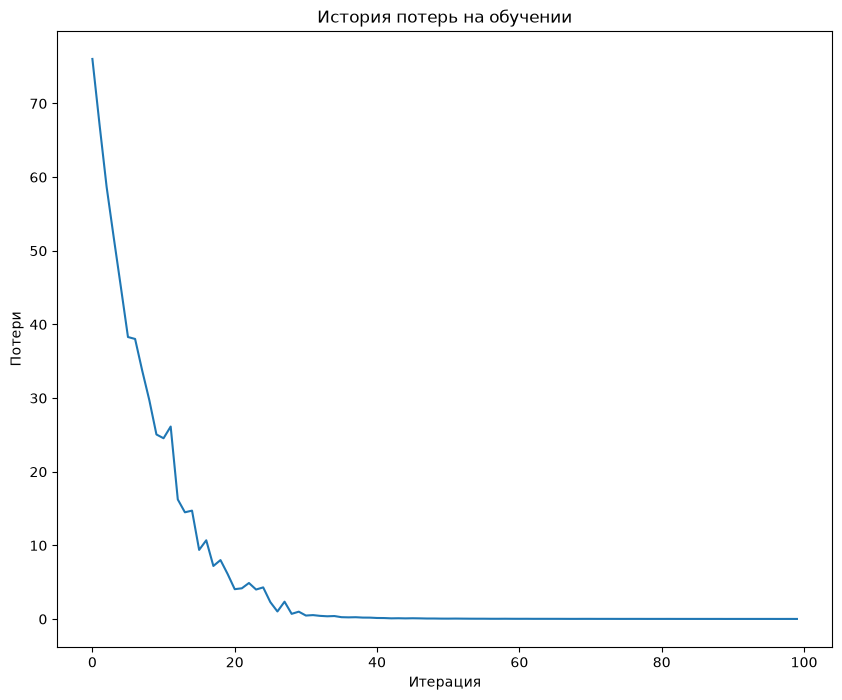

In [15]:
np.random.seed(231)
torch.manual_seed(231)

small_data = load_coco_data(max_train=50)

small_rnn_model = CaptioningRNN(
    cell_type='rnn',
    word_to_idx=data['word_to_idx'],
    input_dim=data['train_features'].shape[1],
    hidden_dim=512,
    wordvec_dim=256,
)

small_rnn_solver = CaptioningSolverPytorch(
    small_rnn_model, small_data,
    num_epochs=50,
    batch_size=25,
    learning_rate=5e-3,
    verbose=True, print_every=10,
)

small_rnn_solver.train()

# Строим график потерь на обучении.
plt.plot(small_rnn_solver.loss_history)
plt.xlabel('Итерация')
plt.ylabel('Потери')
plt.title('История потерь на обучении')
plt.show()

Выведем итоговое значение потерь на обучении. Оно должно быть меньше 0.1.

In [16]:
print('Итоговые потери: ', small_rnn_solver.loss_history[-1])

Итоговые потери:  0.013195577


# Генерация подписей с помощью RNN на этапе тестирования
В отличие от моделей классификации, модели генерации подписей к изображениям ведут себя на этапе обучения и на этапе тестирования совсем по-разному. Во время обучения эталонная подпись известна, поэтому на каждом шаге по времени на вход RNN подаются слова эталонной подписи. Во время тестирования на каждом шаге по времени из распределения по словарю выбирается слово (в этой лабораторной — слово с наибольшей оценкой), и оно подаётся на вход RNN на следующем шаге.

В файле `dlcv/classifiers/rnn_pytorch.py` реализуйте метод `sample` для генерации подписей на этапе тестирования. Затем запустите следующую ячейку, чтобы сгенерировать подписи с помощью переобученной модели и для обучающих, и для валидационных данных. Подписи для обучающих данных должны получиться очень хорошими, а подписи для валидационных данных, скорее всего, окажутся бессмысленными.

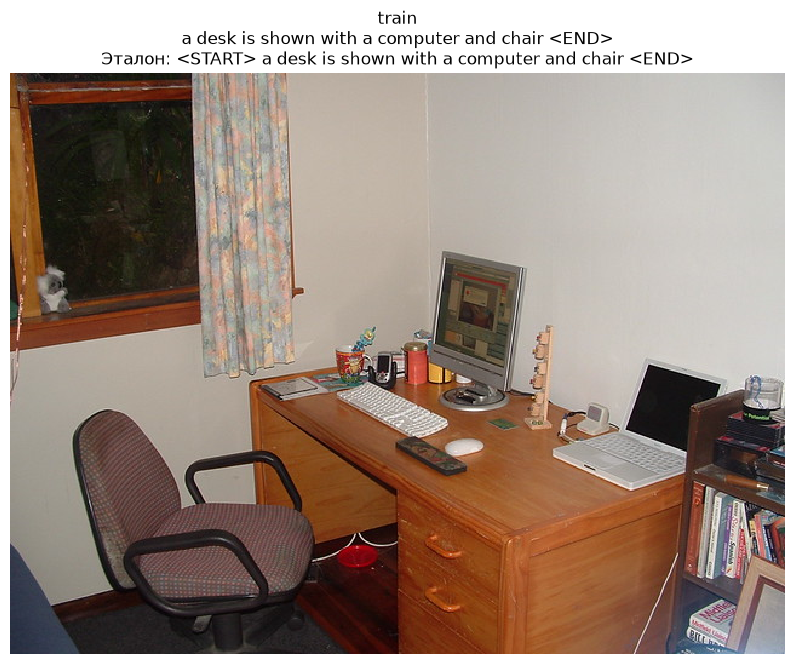

Ошибка HTTP:  404 http://farm8.staticflickr.com/7354/9474081060_3c3e17c790_z.jpg


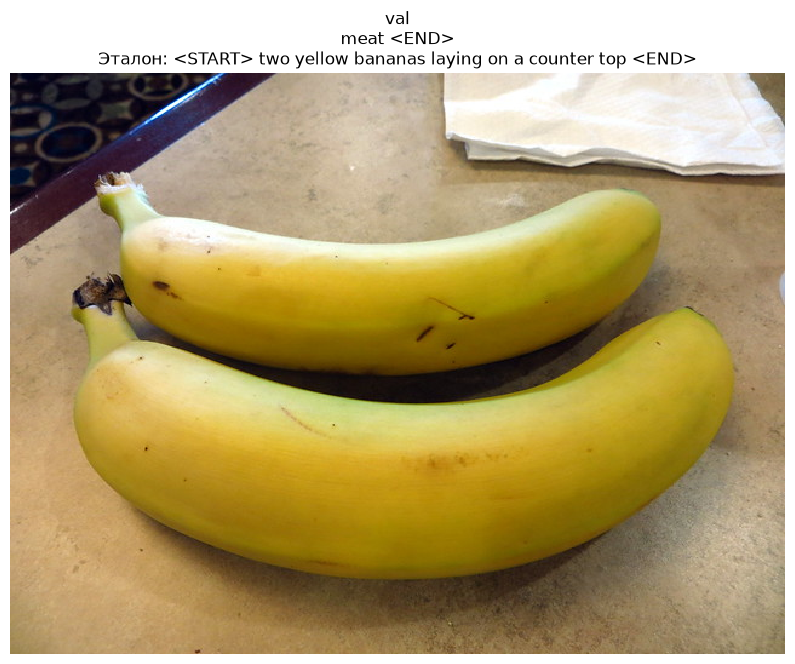

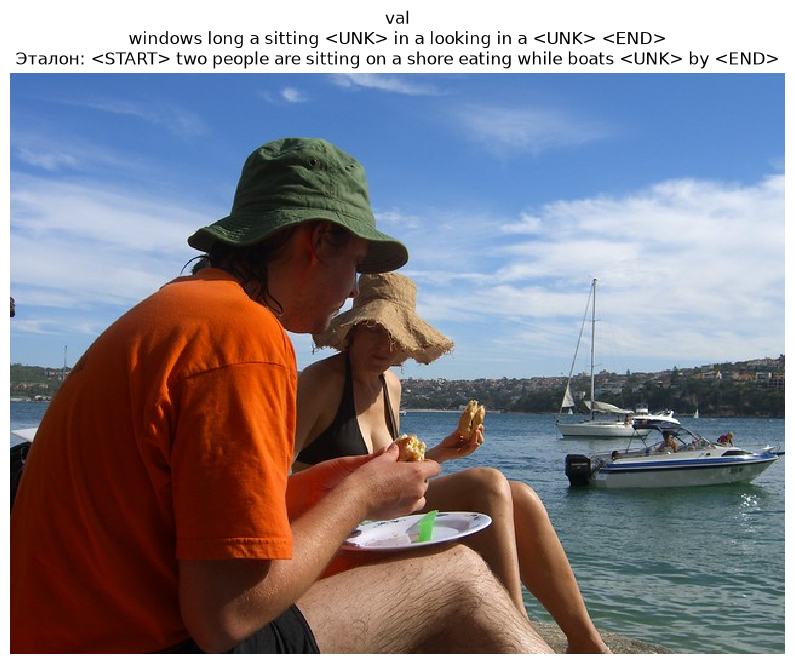

In [17]:
# Если появилось сообщение об ошибке, значит, этого URL больше не существует —
# не волнуйтесь! Выбирать новые примеры можно сколько угодно раз.
for split in ['train', 'val']:
    minibatch = sample_coco_minibatch(small_data, split=split, batch_size=2)
    gt_captions, features, urls = minibatch
    gt_captions = decode_captions(gt_captions, data['idx_to_word'])

    sample_captions = small_rnn_model.sample(torch.from_numpy(features)).numpy()
    sample_captions = decode_captions(sample_captions, data['idx_to_word'])

    for gt_caption, sample_caption, url in zip(gt_captions, sample_captions, urls):
        img = image_from_url(url)
        # Пропускаем недоступные URL.
        if img is None: continue
        plt.imshow(img)
        plt.title('%s\n%s\nЭталон: %s' % (split, sample_caption, gt_caption))
        plt.axis('off')
        plt.show()

# Вопрос 1

В текущей постановке задачи генерации подписей к изображениям наша языковая модель на основе RNN на каждом шаге по времени выдаёт одно слово. Однако задачу можно поставить и иначе: обучить сеть работать не со словами, а с _символами_ (например, 'a', 'b' и т. д.), чтобы на каждом шаге по времени она получала на вход предыдущий символ и пыталась предсказать следующий символ последовательности. Например, сеть может сгенерировать такую подпись:

'A', ' ', 'c', 'a', 't', ' ', 'o', 'n', ' ', 'a', ' ', 'b', 'e', 'd'

Назовите одно преимущество модели генерации подписей к изображениям, которая использует RNN на уровне символов. Назовите также один недостаток такой модели. Подсказка: правильных ответов несколько, но полезно сравнить пространства параметров моделей, работающих на уровне слов и на уровне символов.

**Ваш ответ:** На уровне символов словарь мал: нужны буквы, пробелы и знаки препинания, поэтому матрицы embedding и выхода существенно меньше. Модель может генерировать слова, которых не было в обучающем словаре, и естественно обрабатывать редкие формы и опечатки. Недостаток — гораздо более длинные последовательности: требуется больше шагов RNN, медленнее обучение и генерация, труднее сохранять дальние зависимости и грамматику; сеть должна дополнительно выучить структуру слов. На уровне слов последовательности короче, и каждый шаг уже несёт смысловую единицу, но словарь велик, а неизвестные слова заменяются <UNK>.


### Результат выполненного эксперимента

Фиксированный проверочный loss совпал с эталоном с абсолютной ошибкой 2.61·10⁻¹². На 50 обучающих подписях после 100 итераций итоговый loss составил 0.01320 (< 0.1), то есть модель успешно запомнила малый набор. Это проверка работоспособности обучения, а не качества обобщения на всём COCO. Одна исходная Flickr-ссылка вернула HTTP 404 и была пропущена штатным помощником; остальные примеры и сгенерированные подписи сохранены.